
# AI-Powered Career Guidance Platform
## Model Training, Evaluation and Selection

### Aim
To train, evaluate, and compare multiple machine learning classification
algorithms for predicting suitable career domains from student assessment
features and educational profile information.

### Objectives
1. Load and validate the training and testing datasets.
2. Prepare numerical and categorical features.
3. Establish a baseline using a Dummy Classifier.
4. Train and compare multiple classification algorithms.
5. Evaluate models using cross-validation and classification metrics.
6. Select the three best-performing models based on experimental results.
7. Save the selected models for backend integration.

### Dataset
- Training dataset: career_guidance_train.csv
- Testing dataset: career_guidance_test.csv
- Target: recommended_career_domain
- Expected career domains: 12

### Evaluation Metrics
- Accuracy
- Macro Precision
- Macro Recall
- Macro F1-score
- Confusion Matrix
- Cross-validation stability

### Important Note
The current dataset is synthetic. Model performance will measure learning
on this dataset and will not, by itself, establish real-world career-guidance
accuracy.


In [1]:

# ================================================================
# STEP 11B: IMPORT LIBRARIES AND LOAD DATASETS
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import sklearn

# Dataset directory
BASE_DIR = Path(
    r"C:\B-TECH\ACADEMIC\MLLAB\ML_PROJECT"
    r"\AI_Career_Guidance_Dataset_Package"
    r"\AI_Career_Guidance_Dataset"
)

# Load training and testing datasets
train = pd.read_csv(
    BASE_DIR / "career_guidance_train.csv"
)

test = pd.read_csv(
    BASE_DIR / "career_guidance_test.csv"
)

# Define target
TARGET = "recommended_career_domain"

# Define identifier columns to exclude from model inputs
ID_COLUMNS = ["profile_id"]

# Separate predictors and target
feature_columns = [
    col for col in train.columns
    if col != TARGET and col not in ID_COLUMNS
]

X_train = train[feature_columns].copy()
y_train = train[TARGET].copy()

X_test = test[feature_columns].copy()
y_test = test[TARGET].copy()

# Display dataset information
print("=" * 65)
print("DATASET LOADING AND VALIDATION")
print("=" * 65)

print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("\nTraining dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)

print("\nTraining predictors:", X_train.shape)
print("Testing predictors:", X_test.shape)

print("\nTarget column:", TARGET)
print("Number of predictors:", len(feature_columns))

print("\nPredictor columns:")
print(feature_columns)

print("\nTraining target classes:", y_train.nunique())
print("Testing target classes:", y_test.nunique())

print("\nTraining missing values:", int(X_train.isna().sum().sum()))
print("Testing missing values:", int(X_test.isna().sum().sum()))

print("\nTraining target missing values:", int(y_train.isna().sum()))
print("Testing target missing values:", int(y_test.isna().sum()))

# Validate expected structure
assert TARGET in train.columns
assert TARGET in test.columns
assert list(train.columns) == list(test.columns)
assert X_train.shape[1] == X_test.shape[1]
assert y_train.notna().all()
assert y_test.notna().all()

print("\nDataset loading and basic validation completed.")


DATASET LOADING AND VALIDATION
Pandas version: 3.0.5
Scikit-learn version: 1.9.0

Training dataset shape: (1920, 26)
Testing dataset shape: (480, 26)

Training predictors: (1920, 25)
Testing predictors: (480, 25)

Target column: recommended_career_domain
Number of predictors: 25

Predictor columns:
['age_group', 'education_level', 'experience_stage', 'region_type', 'interest_technology', 'interest_data', 'interest_problem_solving', 'interest_creativity', 'interest_people', 'interest_helping', 'aptitude_logical', 'aptitude_numerical', 'aptitude_verbal', 'aptitude_spatial', 'aptitude_critical_thinking', 'trait_openness', 'trait_conscientiousness', 'trait_extraversion', 'trait_agreeableness', 'trait_emotional_stability', 'skill_programming', 'skill_data_analysis', 'skill_research', 'skill_communication', 'skill_leadership']

Training target classes: 12
Testing target classes: 12

Training missing values: 0
Testing missing values: 0

Training target missing values: 0
Testing target missing

In [3]:

# ================================================================
# STEP 11C: FEATURE TYPES AND PREPROCESSING PIPELINE
# ================================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# ------------------------------------------------
# 1. Identify numerical and categorical features
# ------------------------------------------------

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool", "str"]
).columns.tolist()

print("=" * 65)
print("FEATURE TYPE IDENTIFICATION")
print("=" * 65)

print("\nNumber of numerical features:", len(numeric_features))
print("Numerical features:")
print(numeric_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Categorical features:")
print(categorical_features)

# ------------------------------------------------
# 2. Create numerical preprocessing pipeline
# ------------------------------------------------

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# ------------------------------------------------
# 3. Create categorical preprocessing pipeline
# ------------------------------------------------

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# ------------------------------------------------
# 4. Combine both preprocessing pipelines
# ------------------------------------------------

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# ------------------------------------------------
# 5. Validate feature coverage
# ------------------------------------------------

covered_features = numeric_features + categorical_features
uncovered_features = sorted(
    set(X_train.columns) - set(covered_features)
)

print("\n" + "=" * 65)
print("PREPROCESSING VALIDATION")
print("=" * 65)

print("Total input features:", X_train.shape[1])
print("Features covered:", len(covered_features))
print("Uncovered features:", uncovered_features)

assert len(covered_features) == X_train.shape[1]
assert len(set(covered_features)) == len(covered_features)
assert not uncovered_features

print("\nPreprocessing pipelines created successfully.")
print("Numeric features will be imputed and standardized.")
print("Categorical features will be imputed and one-hot encoded.")
print("The pipelines will be fitted only on training data.")
print("\nStep 11C completed.")


FEATURE TYPE IDENTIFICATION

Number of numerical features: 21
Numerical features:
['interest_technology', 'interest_data', 'interest_problem_solving', 'interest_creativity', 'interest_people', 'interest_helping', 'aptitude_logical', 'aptitude_numerical', 'aptitude_verbal', 'aptitude_spatial', 'aptitude_critical_thinking', 'trait_openness', 'trait_conscientiousness', 'trait_extraversion', 'trait_agreeableness', 'trait_emotional_stability', 'skill_programming', 'skill_data_analysis', 'skill_research', 'skill_communication', 'skill_leadership']

Number of categorical features: 4
Categorical features:
['age_group', 'education_level', 'experience_stage', 'region_type']

PREPROCESSING VALIDATION
Total input features: 25
Features covered: 25
Uncovered features: []

Preprocessing pipelines created successfully.
Numeric features will be imputed and standardized.
Categorical features will be imputed and one-hot encoded.
The pipelines will be fitted only on training data.

Step 11C completed.


In [4]:

# ================================================================
# STEP 11D: DEFINE CANDIDATE CLASSIFICATION MODELS
# ================================================================

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline

# ------------------------------------------------
# 1. Define candidate algorithms
# ------------------------------------------------

candidate_models = {
    "Dummy Classifier": DummyClassifier(
        strategy="prior"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        kernel="rbf",
        C=1.0
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "HistGradient Boosting": HistGradientBoostingClassifier(
        random_state=42
    ),

    "MLP Neural Network": MLPClassifier(
        hidden_layer_sizes=(100, 50),
        max_iter=500,
        early_stopping=True,
        random_state=42
    ),

    "Gaussian Naive Bayes": GaussianNB()
}

# ------------------------------------------------
# 2. Display candidate models
# ------------------------------------------------

print("=" * 65)
print("CANDIDATE CLASSIFICATION MODELS")
print("=" * 65)

for index, model_name in enumerate(candidate_models, start=1):
    print(f"{index}. {model_name}")

print("\nTotal candidate models:", len(candidate_models))
print("Includes a Dummy Classifier baseline.")
print("No models have been trained in this step.")

print("\nStep 11D completed.")


CANDIDATE CLASSIFICATION MODELS
1. Dummy Classifier
2. Logistic Regression
3. KNN
4. SVM
5. Decision Tree
6. Random Forest
7. Extra Trees
8. Gradient Boosting
9. HistGradient Boosting
10. MLP Neural Network
11. Gaussian Naive Bayes

Total candidate models: 11
Includes a Dummy Classifier baseline.
No models have been trained in this step.

Step 11D completed.


In [5]:

import pandas as pd
import numpy as np
import warnings

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Create a dense-output preprocessor.
# Dense output supports all candidate models, including GaussianNB
# and HistGradientBoostingClassifier.

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor_dense = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    sparse_threshold=0
)

# Use 5-fold stratified cross-validation.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}

results = []

print("=" * 70)
print("5-FOLD STRATIFIED CROSS-VALIDATION")
print("=" * 70)

for model_name, model in candidate_models.items():
    print(f"\nEvaluating: {model_name} ...")

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor_dense)),
        ("classifier", clone(model))
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False,
        error_score="raise"
    )

    results.append({
        "Model": model_name,
        "Accuracy_Mean": scores["test_accuracy"].mean(),
        "Accuracy_Std": scores["test_accuracy"].std(),
        "Precision_Macro": scores["test_precision_macro"].mean(),
        "Recall_Macro": scores["test_recall_macro"].mean(),
        "F1_Macro": scores["test_f1_macro"].mean(),
        "Fit_Time_Seconds": scores["fit_time"].mean()
    })

    print(
        f"Accuracy: {scores['test_accuracy'].mean():.4f} | "
        f"Macro F1: {scores['test_f1_macro'].mean():.4f}"
    )

cv_results = pd.DataFrame(results)

cv_results = cv_results.sort_values(
    by="F1_Macro",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("MODEL COMPARISON — RANKED BY MACRO F1")
print("=" * 70)

display(
    cv_results.style.format({
        "Accuracy_Mean": "{:.4f}",
        "Accuracy_Std": "{:.4f}",
        "Precision_Macro": "{:.4f}",
        "Recall_Macro": "{:.4f}",
        "F1_Macro": "{:.4f}",
        "Fit_Time_Seconds": "{:.2f}"
    })
)

cv_results.to_csv("cv_model_comparison.csv", index=False)

print("\nResults saved to: cv_model_comparison.csv")
print("Cross-validation completed. The test dataset has not been used.")


5-FOLD STRATIFIED CROSS-VALIDATION

Evaluating: Dummy Classifier ...


C:\B-TECH\AnacondaFiles\envs\ml\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\B-TECH\AnacondaFiles\envs\ml\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\B-TECH\AnacondaFiles\envs\ml\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\B-TE

Accuracy: 0.0880 | Macro F1: 0.0135

Evaluating: Logistic Regression ...
Accuracy: 0.8281 | Macro F1: 0.8275

Evaluating: KNN ...
Accuracy: 0.5188 | Macro F1: 0.5220

Evaluating: SVM ...
Accuracy: 0.7120 | Macro F1: 0.7123

Evaluating: Decision Tree ...
Accuracy: 0.4786 | Macro F1: 0.4776

Evaluating: Random Forest ...
Accuracy: 0.7703 | Macro F1: 0.7687

Evaluating: Extra Trees ...
Accuracy: 0.8063 | Macro F1: 0.8048

Evaluating: Gradient Boosting ...
Accuracy: 0.7974 | Macro F1: 0.7971

Evaluating: HistGradient Boosting ...
Accuracy: 0.7932 | Macro F1: 0.7928

Evaluating: MLP Neural Network ...
Accuracy: 0.8089 | Macro F1: 0.8087

Evaluating: Gaussian Naive Bayes ...
Accuracy: 0.8385 | Macro F1: 0.8378

MODEL COMPARISON — RANKED BY MACRO F1


,Model,Accuracy_Mean,Accuracy_Std,Precision_Macro,Recall_Macro,F1_Macro,Fit_Time_Seconds
0,Gaussian Naive Bayes,0.8385,0.0130,0.8424,0.8377,0.8378,0.07
1,Logistic Regression,0.8281,0.0099,0.8325,0.8276,0.8275,0.99
2,MLP Neural Network,0.8089,0.0126,0.8129,0.8085,0.8087,3.93
3,Extra Trees,0.8063,0.0190,0.8121,0.8050,0.8048,1.38
4,Gradient Boosting,0.7974,0.0209,0.8040,0.7961,0.7971,25.15
5,HistGradient Boosting,0.7932,0.0071,0.7988,0.7927,0.7928,35.06
6,Random Forest,0.7703,0.0144,0.7726,0.7691,0.7687,1.68
7,SVM,0.7120,0.0153,0.7190,0.7120,0.7123,0.60
8,KNN,0.5188,0.0294,0.5480,0.5212,0.5220,0.07
9,Decision Tree,0.4786,0.0222,0.4809,0.4793,0.4776,0.17



Results saved to: cv_model_comparison.csv
Cross-validation completed. The test dataset has not been used.


In [6]:

# Step 11G: Inspect target distribution and feature relationships

import pandas as pd
import numpy as np

print("=" * 65)
print("1. TARGET CLASS DISTRIBUTION")
print("=" * 65)

print("\nTraining target counts:")
display(y_train.value_counts().sort_values(ascending=False))

print("\nTraining target percentages:")
display(
    (y_train.value_counts(normalize=True) * 100)
    .round(2)
    .sort_values(ascending=False)
)

print("\n" + "=" * 65)
print("2. NUMERIC FEATURE RELATIONSHIPS")
print("=" * 65)

analysis_df = X_train[numeric_features].copy()
analysis_df["target"] = y_train.to_numpy()

class_means = analysis_df.groupby("target")[numeric_features].mean()

print("Shape of career-wise feature averages:", class_means.shape)

display(class_means.round(2))

print("\n" + "=" * 65)
print("3. CHECK CURRENT DATASET FILES")
print("=" * 65)

from pathlib import Path

for filename in [
    "career_guidance_raw_synthetic.csv",
    "career_guidance_processed.csv",
    "career_guidance_train.csv",
    "career_guidance_test.csv",
    "data_dictionary.json",
    "README.md"
]:
    path = Path(filename)
    print(f"{filename}: {'Found' if path.exists() else 'Not found'}")


1. TARGET CLASS DISTRIBUTION

Training target counts:


recommended_career_domain
UI/UX Design                     169
Education & Research             166
Law & Public Service             166
Healthcare & Life Sciences       166
Software Development             164
Data Science & Analytics         161
Engineering & Core Technology    160
Business & Management            160
Digital Marketing                157
Finance & Accounting             151
Creative Arts & Media            151
Cybersecurity                    149
Name: count, dtype: int64


Training target percentages:


recommended_career_domain
UI/UX Design                     8.80
Education & Research             8.65
Law & Public Service             8.65
Healthcare & Life Sciences       8.65
Software Development             8.54
Data Science & Analytics         8.39
Engineering & Core Technology    8.33
Business & Management            8.33
Digital Marketing                8.18
Finance & Accounting             7.86
Creative Arts & Media            7.86
Cybersecurity                    7.76
Name: proportion, dtype: float64


2. NUMERIC FEATURE RELATIONSHIPS
Shape of career-wise feature averages: (12, 21)


,interest_technology,interest_data,interest_problem_solving,interest_creativity,interest_people,interest_helping,aptitude_logical,aptitude_numerical,aptitude_verbal,aptitude_spatial,...,trait_openness,trait_conscientiousness,trait_extraversion,trait_agreeableness,trait_emotional_stability,skill_programming,skill_data_analysis,skill_research,skill_communication,skill_leadership
target,,,,,,,,,,,,,,,,,,,,,
Business & Management,6.99,6.01,7.11,7.82,8.11,6.85,6.91,6.97,6.99,7.88,...,8.02,7.85,7.99,8.08,7.85,6.16,6.04,5.98,7.98,8.76
Creative Arts & Media,6.58,5.00,7.04,9.40,8.83,7.04,7.18,6.02,6.96,8.00,...,6.93,6.94,8.79,6.91,6.93,6.22,4.99,5.84,8.64,8.61
Cybersecurity,8.70,6.77,7.96,6.01,6.89,4.96,7.85,7.91,8.03,7.96,...,8.11,8.01,6.09,7.81,6.93,7.37,6.67,8.87,6.80,5.99
Data Science & Analytics,7.85,8.72,7.83,7.15,6.06,4.88,8.79,9.03,7.97,7.12,...,6.97,7.89,6.75,6.90,5.87,6.81,8.72,5.82,6.93,6.01
Digital Marketing,7.01,5.97,7.83,8.72,7.97,7.01,7.08,6.92,6.93,7.97,...,7.89,7.05,8.02,8.02,7.99,6.05,6.09,5.99,8.75,8.02
Education & Research,6.81,8.02,7.08,7.07,8.19,7.85,7.96,7.93,6.97,6.96,...,8.03,7.82,7.82,7.91,7.92,7.11,7.91,6.19,7.84,7.97
Engineering & Core Technology,8.04,8.03,7.80,6.14,5.96,5.20,8.84,7.88,7.90,7.79,...,7.01,8.10,5.90,6.90,5.90,8.00,7.04,7.18,5.91,4.96
Finance & Accounting,6.07,8.86,5.95,6.01,7.17,5.02,8.02,8.81,6.99,7.06,...,6.87,7.98,6.20,7.95,7.14,6.04,8.58,5.84,5.98,6.71
Healthcare & Life Sciences,7.01,6.83,7.08,6.24,8.02,7.93,8.02,7.04,6.99,6.95,...,8.04,6.98,7.93,7.01,7.88,6.04,6.13,4.89,7.03,8.13



3. CHECK CURRENT DATASET FILES
career_guidance_raw_synthetic.csv: Found
career_guidance_processed.csv: Found
career_guidance_train.csv: Found
career_guidance_test.csv: Found
data_dictionary.json: Found
README.md: Found


In [7]:

# Step 11H: Hyperparameter tuning

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

tuning_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

tuning_models = {
    "Gaussian Naive Bayes": (
        GaussianNB(),
        {
            "classifier__var_smoothing": [
                1e-12, 1e-11, 1e-10, 1e-9, 1e-8, 1e-7
            ]
        }
    ),

    "Logistic Regression": (
        LogisticRegression(max_iter=3000, random_state=42),
        {
            "classifier__C": [0.01, 0.1, 1, 10, 100],
            "classifier__solver": ["lbfgs"],
            "classifier__class_weight": [None, "balanced"]
        }
    ),

    "MLP Neural Network": (
        MLPClassifier(
            max_iter=600,
            early_stopping=True,
            random_state=42
        ),
        {
            "classifier__hidden_layer_sizes": [
                (64,),
                (100,),
                (100, 50),
                (128, 64)
            ],
            "classifier__alpha": [0.0001, 0.001, 0.01],
            "classifier__learning_rate_init": [0.001, 0.01]
        }
    )
}

tuning_results = []
best_estimators = {}

for model_name, (model, param_grid) in tuning_models.items():
    print(f"\nTuning {model_name}...")

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor_dense)),
        ("classifier", clone(model))
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="f1_macro",
        cv=tuning_cv,
        n_jobs=1,
        refit=True,
        verbose=1,
        error_score="raise"
    )

    search.fit(X_train, y_train)

    best_estimators[model_name] = search.best_estimator_

    tuning_results.append({
        "Model": model_name,
        "Best_CV_Accuracy": search.best_estimator_.score(
            X_train, y_train
        ),
        "Best_CV_Macro_F1": search.best_score_,
        "Best_Parameters": search.best_params_
    })

    print("Best CV Macro F1:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

tuning_results_df = pd.DataFrame(tuning_results)

display(
    tuning_results_df[
        ["Model", "Best_CV_Macro_F1", "Best_Parameters"]
    ]
)

tuning_results_df.to_csv(
    "hyperparameter_tuning_results.csv",
    index=False
)

print("\nSaved: hyperparameter_tuning_results.csv")



Tuning Gaussian Naive Bayes...
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best CV Macro F1: 0.8378
Best parameters: {'classifier__var_smoothing': 1e-12}

Tuning Logistic Regression...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best CV Macro F1: 0.8306
Best parameters: {'classifier__C': 10, 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}

Tuning MLP Neural Network...
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best CV Macro F1: 0.8225
Best parameters: {'classifier__alpha': 0.001, 'classifier__hidden_layer_sizes': (100,), 'classifier__learning_rate_init': 0.01}


,Model,Best_CV_Macro_F1,Best_Parameters
0,Gaussian Naive Bayes,0.837824,{'classifier__var_smoothing': 1e-12}
1,Logistic Regression,0.830593,"{'classifier__C': 10, 'classifier__class_weigh..."
2,MLP Neural Network,0.822487,"{'classifier__alpha': 0.001, 'classifier__hidd..."



Saved: hyperparameter_tuning_results.csv


In [8]:

# Step 11I: Compare tuned models and a soft-voting ensemble

from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.ensemble import VotingClassifier, ExtraTreesClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
import pandas as pd

evaluation_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Use the best configurations discovered during tuning.
models_to_evaluate = {
    name: clone(best_estimators[name])
    for name in [
        "Gaussian Naive Bayes",
        "Logistic Regression",
        "MLP Neural Network"
    ]
}

# Add Extra Trees with the same preprocessing.
models_to_evaluate["Extra Trees"] = Pipeline([
    ("preprocessor", clone(preprocessor_dense)),
    ("classifier", ExtraTreesClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Combine the four models using probability averaging.
voting_model = VotingClassifier(
    estimators=[
        ("gnb", clone(best_estimators["Gaussian Naive Bayes"])),
        ("lr", clone(best_estimators["Logistic Regression"])),
        ("mlp", clone(best_estimators["MLP Neural Network"])),
        ("extra_trees", clone(models_to_evaluate["Extra Trees"]))
    ],
    voting="soft"
)

models_to_evaluate["Soft Voting Ensemble"] = voting_model

comparison = []

for name, model in models_to_evaluate.items():
    print(f"Evaluating {name}...")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=evaluation_cv,
        scoring={
            "accuracy": "accuracy",
            "f1_macro": "f1_macro"
        },
        n_jobs=1,
        error_score="raise"
    )

    comparison.append({
        "Model": name,
        "CV_Accuracy_Mean": scores["test_accuracy"].mean(),
        "CV_Accuracy_Std": scores["test_accuracy"].std(),
        "CV_Macro_F1": scores["test_f1_macro"].mean()
    })

ensemble_results = (
    pd.DataFrame(comparison)
    .sort_values("CV_Accuracy_Mean", ascending=False)
    .reset_index(drop=True)
)

display(ensemble_results.round(4))

ensemble_results.to_csv(
    "ensemble_model_comparison.csv",
    index=False
)

print("\nSaved: ensemble_model_comparison.csv")
print("Test dataset remains untouched.")


Evaluating Gaussian Naive Bayes...
Evaluating Logistic Regression...
Evaluating MLP Neural Network...
Evaluating Extra Trees...
Evaluating Soft Voting Ensemble...


,Model,CV_Accuracy_Mean,CV_Accuracy_Std,CV_Macro_F1
0,Soft Voting Ensemble,0.8438,0.0120,0.8429
1,Gaussian Naive Bayes,0.8385,0.0130,0.8378
2,Logistic Regression,0.8318,0.0134,0.8306
3,MLP Neural Network,0.8234,0.0092,0.8225
4,Extra Trees,0.8062,0.0190,0.8048



Saved: ensemble_model_comparison.csv
Test dataset remains untouched.


In [9]:

# Step 11J: Inspect dataset documentation

from pathlib import Path
import json

readme_path = Path("README.md")
dictionary_path = Path("data_dictionary.json")

print("=" * 65)
print("DATASET README")
print("=" * 65)

if readme_path.exists():
    print(readme_path.read_text(encoding="utf-8"))
else:
    print("README.md not found.")

print("\n" + "=" * 65)
print("DATA DICTIONARY")
print("=" * 65)

if dictionary_path.exists():
    with open(dictionary_path, "r", encoding="utf-8") as file:
        data_dictionary = json.load(file)

    print(json.dumps(data_dictionary, indent=2, ensure_ascii=False))
else:
    print("data_dictionary.json not found.")


DATASET README
# AI-Powered Career Guidance — Dataset Package

## Files
- `career_guidance_raw_synthetic.csv`: synthetic raw data, includes missing values and 12 intentionally injected duplicate rows.
- `career_guidance_processed.csv`: duplicates removed, numeric missing values imputed with medians, numeric assessment scores normalized to [0, 1].
- `career_guidance_train.csv`: 80% training split from cleaned raw data, with original 1–10 score scale.
- `career_guidance_test.csv`: 20% test split from cleaned raw data, with original 1–10 score scale.
- `data_dictionary.json`: feature definitions and limitations.

## Dataset design
- Intended for prototyping an ML career-domain classifier/recommender.
- 12 target domains.
- 24 assessment features (6 interests, 5 aptitude indicators, 5 personality-trait indicators, 5 skills, plus 4 profile/context categorical fields).
- `profile_id` is an identifier and must not be used as a predictive feature.

## Important methodological note
This is **sy

In [10]:

# Step 11K: Inspect raw synthetic dataset patterns

import pandas as pd
import numpy as np

raw_df = pd.read_csv("career_guidance_raw_synthetic.csv")

TARGET = "recommended_career_domain"

print("=" * 65)
print("1. RAW DATASET OVERVIEW")
print("=" * 65)

print("Shape:", raw_df.shape)
print("Missing cells:", raw_df.isna().sum().sum())
print("Duplicate rows:", raw_df.duplicated().sum())

print("\n" + "=" * 65)
print("2. TARGET LABEL COUNTS")
print("=" * 65)

display(raw_df[TARGET].value_counts(dropna=False))

print("\n" + "=" * 65)
print("3. RAW DATA SAMPLE")
print("=" * 65)

display(raw_df.head(10))

print("\n" + "=" * 65)
print("4. IDENTIFY FEATURES WITH STRONG CAREER-DOMAIN DIFFERENCES")
print("=" * 65)

raw_numeric_features = raw_df.select_dtypes(
    include=["number"]
).columns.tolist()

raw_numeric_features = [
    col for col in raw_numeric_features
    if col != "profile_id"
]

feature_means = raw_df.groupby(TARGET)[raw_numeric_features].mean()

feature_variation = (
    feature_means.max(axis=0) - feature_means.min(axis=0)
).sort_values(ascending=False)

display(feature_variation.to_frame("Difference_Between_Max_Min_Class_Means"))

print("\nTop 10 features with the largest differences in class means:")
print(feature_variation.head(10).index.tolist())


1. RAW DATASET OVERVIEW
Shape: (2412, 27)
Missing cells: 72
Duplicate rows: 12

2. TARGET LABEL COUNTS


recommended_career_domain
UI/UX Design                     212
Law & Public Service             210
Education & Research             209
Healthcare & Life Sciences       207
Software Development             205
Data Science & Analytics         203
Engineering & Core Technology    202
Business & Management            201
Digital Marketing                196
Finance & Accounting             191
Creative Arts & Media            189
Cybersecurity                    187
Name: count, dtype: int64


3. RAW DATA SAMPLE


,profile_id,age_group,education_level,experience_stage,region_type,interest_technology,interest_data,interest_problem_solving,interest_creativity,interest_people,...,trait_conscientiousness,trait_extraversion,trait_agreeableness,trait_emotional_stability,skill_programming,skill_data_analysis,skill_research,skill_communication,skill_leadership,recommended_career_domain
0,CG00001,15-18,B.Sc Mathematics,1-3 years,Rural,6.3,10.0,9.6,3.8,3.9,...,9.6,7.7,5.8,6.5,5.4,10.0,5.9,6.7,4.8,Data Science & Analytics
1,CG00002,15-18,B.Sc Mathematics,Student,Rural,5.4,9.9,6.6,6.7,7.7,...,6.8,4.8,8.9,8.0,6.9,7.9,6.4,6.2,7.4,Finance & Accounting
2,CG00003,31+,B.Tech Mechanical,Student,Rural,8.1,8.5,9.0,3.6,5.5,...,7.5,6.2,7.8,7.0,9.3,6.4,6.2,7.5,4.7,Engineering & Core Technology
3,CG00004,23-30,B.Tech Mechanical,Student,Semi-urban,8.8,8.2,9.1,5.3,6.3,...,8.7,5.3,7.0,6.7,8.8,8.1,6.8,5.3,4.9,Engineering & Core Technology
4,CG00005,15-18,BBA,Entry-level,Semi-urban,5.4,6.7,5.5,7.4,10.0,...,5.6,8.6,8.3,7.2,3.5,6.1,5.1,8.4,9.0,Business & Management
5,CG00006,23-30,BBA,Student,Semi-urban,7.3,6.4,10.0,10.0,8.6,...,6.7,5.9,6.6,8.4,7.4,9.4,10.0,9.7,6.3,Digital Marketing
6,CG00007,15-18,BA Political Science,Student,Rural,6.3,6.0,6.8,7.8,8.3,...,9.4,7.3,7.3,6.6,5.8,10.0,4.6,9.4,6.5,Law & Public Service
7,CG00008,15-18,BA,Student,Rural,6.9,4.9,8.7,8.2,6.0,...,7.3,7.4,9.5,8.6,8.6,6.3,3.9,6.7,10.0,Digital Marketing
8,CG00009,31+,B.Com,Entry-level,Urban,8.4,7.2,4.5,7.1,6.3,...,7.9,4.8,6.3,5.8,5.4,10.0,3.7,6.1,6.2,Finance & Accounting
9,CG00010,31+,MA,1-3 years,Semi-urban,9.2,7.7,5.9,6.6,8.4,...,7.6,6.0,7.2,8.4,9.0,6.8,4.9,4.3,7.7,Education & Research



4. IDENTIFY FEATURES WITH STRONG CAREER-DOMAIN DIFFERENCES


,Difference_Between_Max_Min_Class_Means
skill_research,4.031104
skill_data_analysis,4.027677
interest_data,3.928695
skill_leadership,3.892461
interest_helping,3.874844
interest_creativity,3.328195
aptitude_numerical,3.122646
trait_extraversion,2.915351
interest_problem_solving,2.871403
interest_technology,2.807316



Top 10 features with the largest differences in class means:
['skill_research', 'skill_data_analysis', 'interest_data', 'skill_leadership', 'interest_helping', 'interest_creativity', 'aptitude_numerical', 'trait_extraversion', 'interest_problem_solving', 'interest_technology']


In [11]:
# Step 11L: Compare Important Features Across Career Domains

import pandas as pd

raw_df = pd.read_csv("career_guidance_raw_synthetic.csv")

TARGET = "recommended_career_domain"

important_features = [
    "skill_research",
    "skill_data_analysis",
    "interest_data",
    "skill_leadership",
    "interest_helping",
    "interest_creativity",
    "aptitude_numerical",
    "trait_extraversion",
    "interest_problem_solving",
    "interest_technology"
]

# Calculate average feature scores for each career domain
career_profiles = raw_df.groupby(TARGET)[important_features].mean()

# Display scores rounded to two decimal places
display(career_profiles.round(2))

print("\n" + "=" * 70)
print("HIGHEST-SCORING CAREER DOMAIN FOR EACH FEATURE")
print("=" * 70)

for feature in important_features:
    highest_domain = career_profiles[feature].idxmax()
    highest_score = career_profiles[feature].max()

    print(
        f"{feature}: {highest_domain} "
        f"(average score: {highest_score:.2f})"
    )

,skill_research,skill_data_analysis,interest_data,skill_leadership,interest_helping,interest_creativity,aptitude_numerical,trait_extraversion,interest_problem_solving,interest_technology
recommended_career_domain,,,,,,,,,,
Business & Management,6.04,6.11,6.03,8.78,6.88,7.93,6.98,8.03,7.07,6.90
Creative Arts & Media,5.82,5.05,4.98,8.60,7.18,9.31,6.02,8.81,6.97,6.70
Cybersecurity,8.92,6.68,6.74,5.99,4.93,5.99,7.97,6.08,7.86,8.77
Data Science & Analytics,5.82,8.76,8.73,6.04,4.91,7.15,8.99,6.75,7.86,7.83
Digital Marketing,5.87,6.16,6.01,7.89,6.95,8.75,7.04,8.03,7.85,6.99
Education & Research,6.07,7.80,7.99,7.92,7.88,7.02,7.96,7.85,7.01,6.80
Engineering & Core Technology,7.26,6.92,7.91,4.88,5.17,6.11,7.82,5.90,7.88,8.01
Finance & Accounting,5.82,8.61,8.88,6.71,5.05,6.01,8.78,6.21,5.85,5.97
Healthcare & Life Sciences,4.89,6.13,6.90,8.06,7.88,6.10,7.05,7.97,7.07,6.92



HIGHEST-SCORING CAREER DOMAIN FOR EACH FEATURE
skill_research: Cybersecurity (average score: 8.92)
skill_data_analysis: Data Science & Analytics (average score: 8.76)
interest_data: Finance & Accounting (average score: 8.88)
skill_leadership: Business & Management (average score: 8.78)
interest_helping: Law & Public Service (average score: 8.79)
interest_creativity: Creative Arts & Media (average score: 9.31)
aptitude_numerical: Data Science & Analytics (average score: 8.99)
trait_extraversion: Creative Arts & Media (average score: 8.81)
interest_problem_solving: Software Development (average score: 8.73)
interest_technology: Cybersecurity (average score: 8.77)


In [13]:
# Step 11M: Evaluate Top-1 and Top-3 Cross-Validation Performance

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

top1_scores = []
top3_scores = []
macro_f1_scores = []

for train_idx, val_idx in cv.split(X_train, y_train):
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    # Fit a fresh copy of the selected ensemble
    fold_model = clone(soft_voting_ensemble)
    fold_model.fit(X_fold_train, y_fold_train)

    # Predicted class and class probabilities
    predictions = fold_model.predict(X_fold_val)
    probabilities = fold_model.predict_proba(X_fold_val)

    class_labels = fold_model.classes_

    top1_scores.append(
        accuracy_score(y_fold_val, predictions)
    )

    top3_scores.append(
        top_k_accuracy_score(
            y_fold_val,
            probabilities,
            k=3,
            labels=class_labels
        )
    )

    macro_f1_scores.append(
        f1_score(y_fold_val, predictions, average="macro")
    )

results = pd.DataFrame({
    "Metric": [
        "Top-1 Accuracy",
        "Top-3 Accuracy",
        "Macro F1"
    ],
    "Mean_CV_Score": [
        np.mean(top1_scores),
        np.mean(top3_scores),
        np.mean(macro_f1_scores)
    ],
    "Std_CV_Score": [
        np.std(top1_scores),
        np.std(top3_scores),
        np.std(macro_f1_scores)
    ]
})

display(results.round(4))

NameError: name 'soft_voting_ensemble' is not defined

In [14]:
# Find existing ensemble-related variables

ensemble_variables = [
    name for name in globals()
    if "ensemble" in name.lower() or "voting" in name.lower()
]

print("Ensemble-related variables found:")
print(ensemble_variables)

Ensemble-related variables found:
['VotingClassifier', 'voting_model', 'ensemble_results']


In [15]:
# Step 11M: Evaluate Top-1 and Top-3 Cross-Validation Performance

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

top1_scores = []
top3_scores = []
macro_f1_scores = []

for train_idx, val_idx in cv.split(X_train, y_train):
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    fold_model = clone(voting_model)
    fold_model.fit(X_fold_train, y_fold_train)

    predictions = fold_model.predict(X_fold_val)
    probabilities = fold_model.predict_proba(X_fold_val)

    top1_scores.append(
        accuracy_score(y_fold_val, predictions)
    )

    top3_scores.append(
        top_k_accuracy_score(
            y_fold_val,
            probabilities,
            k=3,
            labels=fold_model.classes_
        )
    )

    macro_f1_scores.append(
        f1_score(y_fold_val, predictions, average="macro")
    )

results = pd.DataFrame({
    "Metric": ["Top-1 Accuracy", "Top-3 Accuracy", "Macro F1"],
    "Mean_CV_Score": [
        np.mean(top1_scores),
        np.mean(top3_scores),
        np.mean(macro_f1_scores)
    ],
    "Std_CV_Score": [
        np.std(top1_scores),
        np.std(top3_scores),
        np.std(macro_f1_scores)
    ]
})

display(results.round(4))

,Metric,Mean_CV_Score,Std_CV_Score
0,Top-1 Accuracy,0.8438,0.012
1,Top-3 Accuracy,0.9849,0.003
2,Macro F1,0.8429,0.011


In [16]:
# Step 11N: Save Cross-Validation Results

results.to_csv(
    "soft_voting_cross_validation_results.csv",
    index=False
)

print("Cross-validation results saved successfully.")
print("File: soft_voting_cross_validation_results.csv")

Cross-validation results saved successfully.
File: soft_voting_cross_validation_results.csv


In [17]:
# Step 11O: Final Evaluation on the Untouched Test Set

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    top_k_accuracy_score
)

# Create a fresh copy of the selected model
final_model = clone(voting_model)

# Train on the complete training dataset
final_model.fit(X_train, y_train)

# Evaluate on the untouched test dataset
y_test_pred = final_model.predict(X_test)
y_test_proba = final_model.predict_proba(X_test)

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(
    y_test, y_test_pred, average="macro", zero_division=0
)
test_recall = recall_score(
    y_test, y_test_pred, average="macro", zero_division=0
)
test_macro_f1 = f1_score(
    y_test, y_test_pred, average="macro", zero_division=0
)
test_top3_accuracy = top_k_accuracy_score(
    y_test,
    y_test_proba,
    k=3,
    labels=final_model.classes_
)

test_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Top-3 Accuracy"
    ],
    "Test Score": [
        test_accuracy,
        test_precision,
        test_recall,
        test_macro_f1,
        test_top3_accuracy
    ]
})

print("FINAL TEST-SET RESULTS")
display(test_results.round(4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_test_pred,
    labels=final_model.classes_,
    zero_division=0
))

FINAL TEST-SET RESULTS


,Metric,Test Score
0,Accuracy,0.8333
1,Macro Precision,0.8348
2,Macro Recall,0.8331
3,Macro F1,0.8314
4,Top-3 Accuracy,0.9917



CLASSIFICATION REPORT
                               precision    recall  f1-score   support

        Business & Management       0.71      0.50      0.59        40
        Creative Arts & Media       0.81      0.76      0.78        38
                Cybersecurity       0.81      0.92      0.86        38
     Data Science & Analytics       0.89      0.85      0.87        40
            Digital Marketing       0.67      0.72      0.69        39
         Education & Research       0.86      0.90      0.88        41
Engineering & Core Technology       0.97      0.90      0.94        40
         Finance & Accounting       0.97      0.95      0.96        38
   Healthcare & Life Sciences       1.00      1.00      1.00        41
         Law & Public Service       0.84      0.86      0.85        42
         Software Development       0.75      0.80      0.78        41
                 UI/UX Design       0.73      0.83      0.78        42

                     accuracy                       

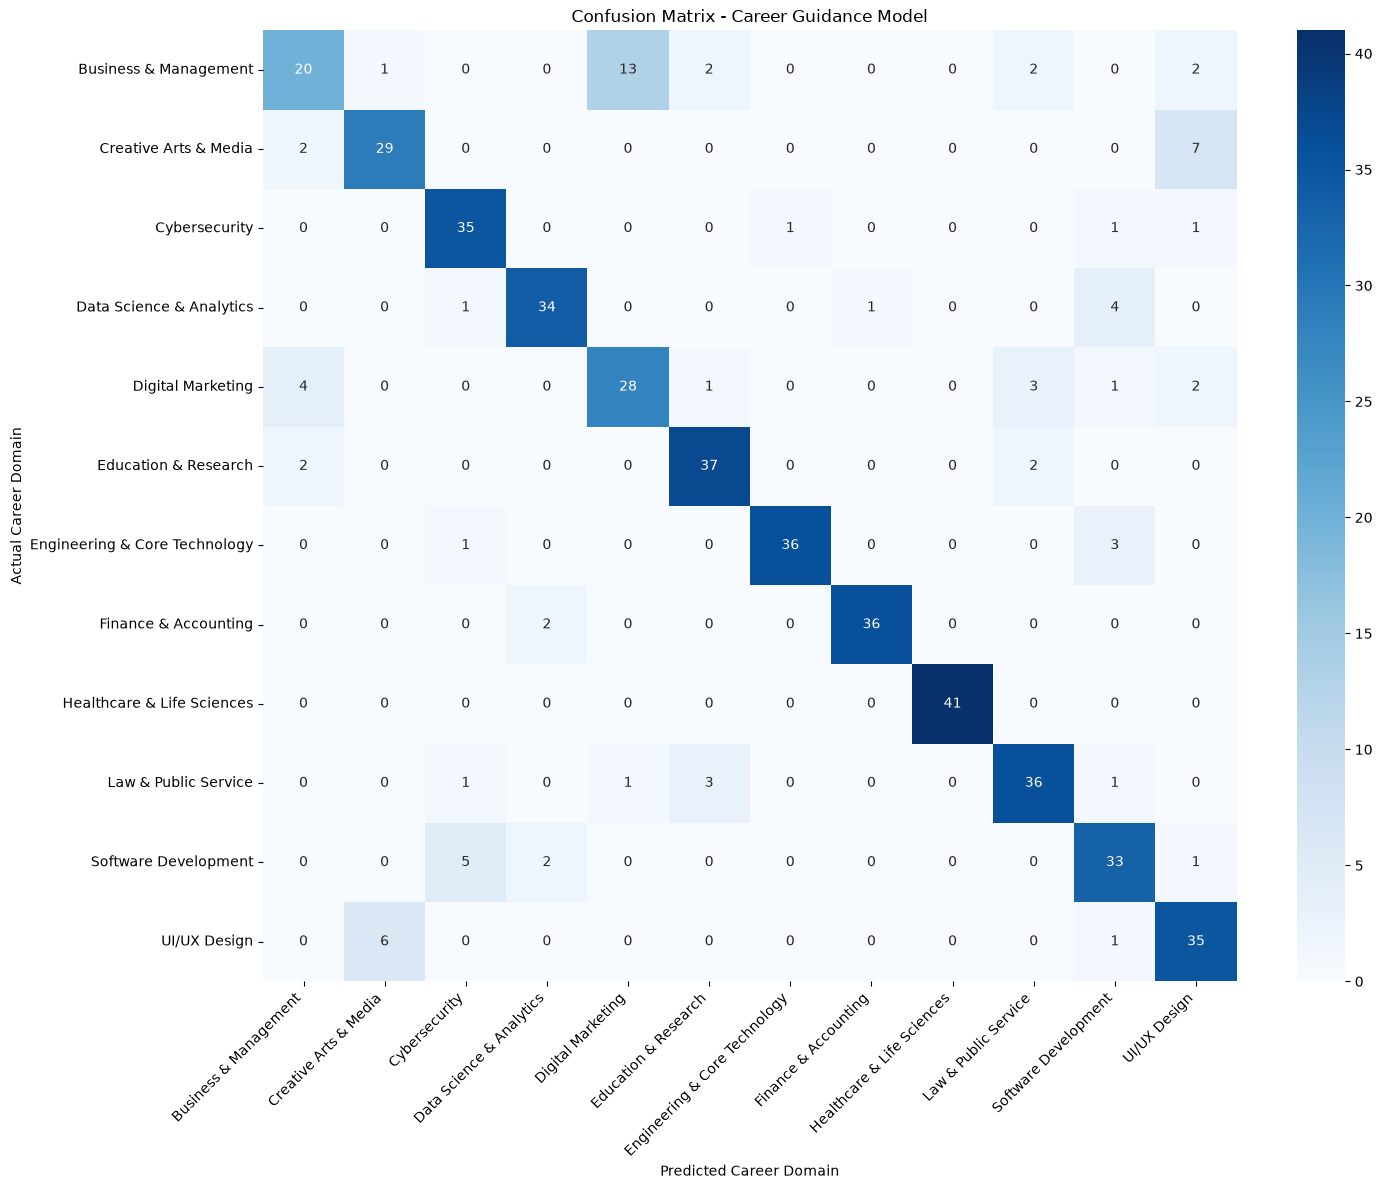

In [18]:
# Step 11P: Confusion Matrix for the Final Model

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

class_labels = final_model.classes_

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=class_labels
)

plt.figure(figsize=(15, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Confusion Matrix - Career Guidance Model")
plt.xlabel("Predicted Career Domain")
plt.ylabel("Actual Career Domain")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

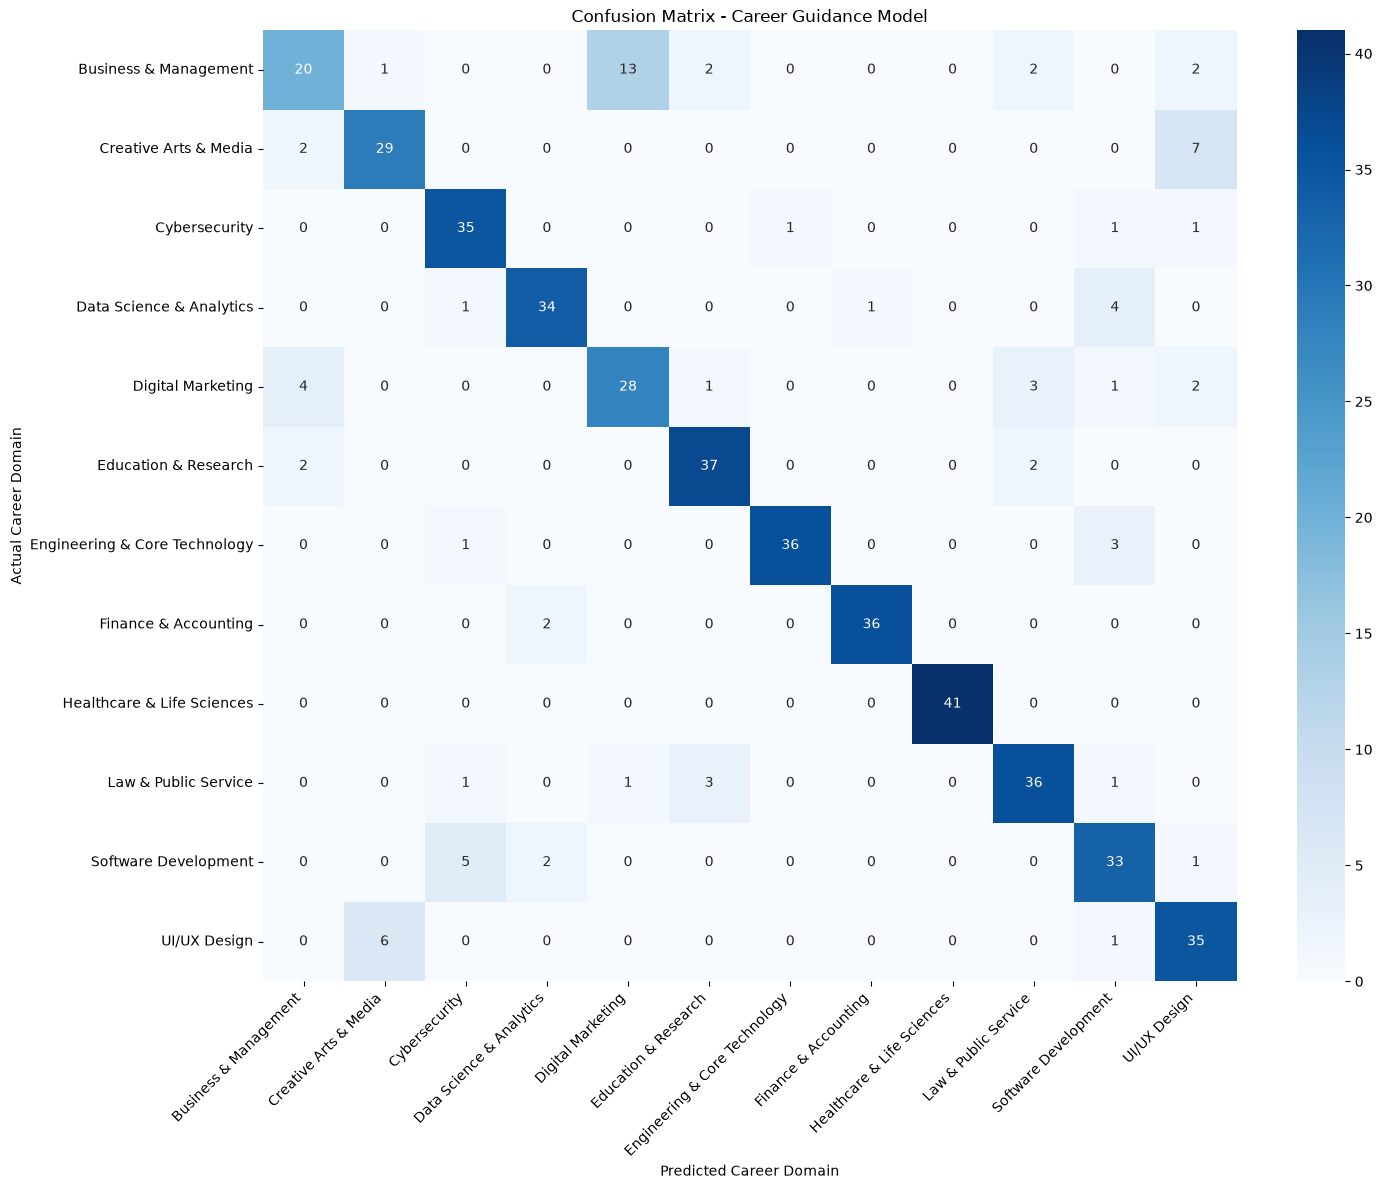

All final evaluation artifacts saved successfully.
1. final_confusion_matrix.csv
2. final_test_evaluation_metrics.csv
3. final_classification_report.csv
4. final_confusion_matrix.png


In [20]:
# Step 11Q: Save Final Evaluation Artifacts

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

# Save confusion matrix as CSV
class_labels = final_model.classes_

cm_df = pd.DataFrame(
    cm,
    index=class_labels,
    columns=class_labels
)

cm_df.index.name = "Actual Career Domain"
cm_df.to_csv("final_confusion_matrix.csv")

# Save the evaluation metrics
test_results.to_csv(
    "final_test_evaluation_metrics.csv",
    index=False
)

# Save the detailed classification report
report = classification_report(
    y_test,
    y_test_pred,
    labels=class_labels,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    "final_classification_report.csv"
)

# Save the confusion matrix figure
fig, ax = plt.subplots(figsize=(15, 12))

import seaborn as sns

sns.heatmap(
    cm_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=ax
)

ax.set_title("Confusion Matrix - Career Guidance Model")
ax.set_xlabel("Predicted Career Domain")
ax.set_ylabel("Actual Career Domain")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

fig.savefig(
    "final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("All final evaluation artifacts saved successfully.")
print("1. final_confusion_matrix.csv")
print("2. final_test_evaluation_metrics.csv")
print("3. final_classification_report.csv")
print("4. final_confusion_matrix.png")

In [21]:
# Step 11R: Investigate Misclassified Profiles

import pandas as pd
import numpy as np

# Combine actual and predicted labels
error_analysis = X_test.copy()

error_analysis["Actual_Career"] = np.asarray(y_test)
error_analysis["Predicted_Career"] = np.asarray(y_test_pred)

error_analysis["Correct_Prediction"] = (
    error_analysis["Actual_Career"]
    == error_analysis["Predicted_Career"]
)

misclassified = error_analysis[
    ~error_analysis["Correct_Prediction"]
].copy()

print("Total test records:", len(error_analysis))
print("Misclassified records:", len(misclassified))
print(
    "Test accuracy:",
    round(error_analysis["Correct_Prediction"].mean() * 100, 2),
    "%"
)

print("\nMost frequent classification errors:")

error_pairs = (
    misclassified.groupby(
        ["Actual_Career", "Predicted_Career"]
    )
    .size()
    .sort_values(ascending=False)
    .reset_index(name="Error_Count")
)

display(error_pairs.head(15))

print("\nAssessment features available for analysis:")

numeric_features = X_test.select_dtypes(
    include=["number"]
).columns.tolist()

print(numeric_features)

Total test records: 480
Misclassified records: 80
Test accuracy: 83.33 %

Most frequent classification errors:


,Actual_Career,Predicted_Career,Error_Count
0,Business & Management,Digital Marketing,13
1,Creative Arts & Media,UI/UX Design,7
2,UI/UX Design,Creative Arts & Media,6
3,Software Development,Cybersecurity,5
4,Data Science & Analytics,Software Development,4
5,Digital Marketing,Business & Management,4
6,Digital Marketing,Law & Public Service,3
7,Engineering & Core Technology,Software Development,3
8,Law & Public Service,Education & Research,3
9,Education & Research,Law & Public Service,2



Assessment features available for analysis:
['interest_technology', 'interest_data', 'interest_problem_solving', 'interest_creativity', 'interest_people', 'interest_helping', 'aptitude_logical', 'aptitude_numerical', 'aptitude_verbal', 'aptitude_spatial', 'aptitude_critical_thinking', 'trait_openness', 'trait_conscientiousness', 'trait_extraversion', 'trait_agreeableness', 'trait_emotional_stability', 'skill_programming', 'skill_data_analysis', 'skill_research', 'skill_communication', 'skill_leadership']


In [22]:
# Step 11S: Compare Business and Digital Marketing Profiles

numeric_features = X_test.select_dtypes(
    include=["number"]
).columns.tolist()

# Correctly classified Business & Management profiles
business_correct = error_analysis[
    (error_analysis["Actual_Career"] == "Business & Management") &
    (error_analysis["Correct_Prediction"])
]

# Business profiles incorrectly predicted as Digital Marketing
business_as_marketing = error_analysis[
    (error_analysis["Actual_Career"] == "Business & Management") &
    (error_analysis["Predicted_Career"] == "Digital Marketing")
]

# Correctly classified Digital Marketing profiles
marketing_correct = error_analysis[
    (error_analysis["Actual_Career"] == "Digital Marketing") &
    (error_analysis["Correct_Prediction"])
]

print("Number of profiles in each group:")
print("Correct Business profiles:", len(business_correct))
print("Business predicted as Marketing:", len(business_as_marketing))
print("Correct Marketing profiles:", len(marketing_correct))

profile_comparison = pd.DataFrame({
    "Business_Correct": business_correct[numeric_features].mean(),
    "Business_Predicted_As_Marketing": business_as_marketing[numeric_features].mean(),
    "Marketing_Correct": marketing_correct[numeric_features].mean()
})

print("\nAverage assessment scores (rounded to 2 decimals):")
display(profile_comparison.round(2))

print("\nLargest score differences between correctly classified")
print("Business profiles and misclassified Business profiles:")

profile_comparison["Absolute_Difference"] = (
    profile_comparison["Business_Correct"] -
    profile_comparison["Business_Predicted_As_Marketing"]
).abs()

display(
    profile_comparison[
        ["Business_Correct", "Business_Predicted_As_Marketing",
         "Absolute_Difference"]
    ]
    .sort_values("Absolute_Difference", ascending=False)
    .head(10)
    .round(2)
)

Number of profiles in each group:
Correct Business profiles: 20
Business predicted as Marketing: 13
Correct Marketing profiles: 28

Average assessment scores (rounded to 2 decimals):


,Business_Correct,Business_Predicted_As_Marketing,Marketing_Correct
interest_technology,6.28,6.85,6.99
interest_data,6.28,5.49,6.02
interest_problem_solving,6.44,7.80,8.15
interest_creativity,8.25,8.62,9.08
interest_people,7.64,8.01,7.78
interest_helping,6.90,7.07,6.85
aptitude_logical,6.86,7.55,7.00
aptitude_numerical,7.04,6.91,7.59
aptitude_verbal,7.13,7.75,6.75
aptitude_spatial,7.65,7.97,7.73



Largest score differences between correctly classified
Business profiles and misclassified Business profiles:


,Business_Correct,Business_Predicted_As_Marketing,Absolute_Difference
interest_problem_solving,6.44,7.80,1.36
skill_communication,7.30,8.22,0.91
trait_openness,8.40,7.58,0.82
interest_data,6.28,5.49,0.79
skill_leadership,9.28,8.55,0.73
aptitude_logical,6.86,7.55,0.69
skill_programming,6.04,5.40,0.63
aptitude_verbal,7.13,7.75,0.63
interest_technology,6.28,6.85,0.56
trait_conscientiousness,8.08,7.56,0.52


In [23]:
# Step 11T: Statistical Analysis of Business Profile Differences

import pandas as pd
from scipy.stats import mannwhitneyu

features_to_test = [
    "interest_problem_solving",
    "skill_communication",
    "trait_openness",
    "interest_data",
    "skill_leadership",
    "aptitude_logical",
    "skill_programming",
    "aptitude_verbal",
    "interest_technology",
    "trait_conscientiousness"
]

statistical_results = []

for feature in features_to_test:
    group_correct = business_correct[feature].dropna()
    group_misclassified = business_as_marketing[feature].dropna()

    statistic, p_value = mannwhitneyu(
        group_correct,
        group_misclassified,
        alternative="two-sided"
    )

    statistical_results.append({
        "Feature": feature,
        "Business_Correct_Median": group_correct.median(),
        "Business_Misclassified_Median": group_misclassified.median(),
        "P_Value": p_value
    })

stats_df = pd.DataFrame(statistical_results)

# Correct for testing multiple features
stats_df["Adjusted_P_Value"] = (
    stats_df["P_Value"] * len(stats_df)
).clip(upper=1.0)

stats_df = stats_df.sort_values("Adjusted_P_Value")

display(stats_df.round(4))

,Feature,Business_Correct_Median,Business_Misclassified_Median,P_Value,Adjusted_P_Value
0,interest_problem_solving,6.60,8.4,0.0234,0.2340
3,interest_data,6.10,5.1,0.0832,0.8323
5,aptitude_logical,6.70,7.4,0.0899,0.8992
1,skill_communication,7.25,8.1,0.1354,1.0000
2,trait_openness,8.30,7.6,0.1885,1.0000
4,skill_leadership,9.60,9.0,0.3078,1.0000
6,skill_programming,5.75,5.6,0.5430,1.0000
7,aptitude_verbal,7.30,8.1,0.1558,1.0000
8,interest_technology,6.30,6.7,0.3106,1.0000
9,trait_conscientiousness,8.00,7.3,0.2307,1.0000


In [24]:
# Step 11U: Summarize Major Classification Errors

# Count every actual-to-predicted error pair
error_summary = (
    error_analysis.loc[
        ~error_analysis["Correct_Prediction"],
        ["Actual_Career", "Predicted_Career"]
    ]
    .groupby(["Actual_Career", "Predicted_Career"])
    .size()
    .reset_index(name="Error_Count")
    .sort_values("Error_Count", ascending=False)
    .reset_index(drop=True)
)

print("Total misclassified records:", len(misclassified))
print("\nTop 15 classification error pairs:")

display(error_summary.head(15))

print("\nErrors by actual career domain:")

errors_by_domain = (
    misclassified["Actual_Career"]
    .value_counts()
    .rename_axis("Actual_Career")
    .reset_index(name="Misclassified_Count")
)

display(errors_by_domain)

Total misclassified records: 80

Top 15 classification error pairs:


,Actual_Career,Predicted_Career,Error_Count
0,Business & Management,Digital Marketing,13
1,Creative Arts & Media,UI/UX Design,7
2,UI/UX Design,Creative Arts & Media,6
3,Software Development,Cybersecurity,5
4,Data Science & Analytics,Software Development,4
5,Digital Marketing,Business & Management,4
6,Digital Marketing,Law & Public Service,3
7,Engineering & Core Technology,Software Development,3
8,Law & Public Service,Education & Research,3
9,Education & Research,Law & Public Service,2



Errors by actual career domain:


,Actual_Career,Misclassified_Count
0,Business & Management,20
1,Digital Marketing,11
2,Creative Arts & Media,9
3,Software Development,8
4,UI/UX Design,7
5,Law & Public Service,6
6,Data Science & Analytics,6
7,Education & Research,4
8,Engineering & Core Technology,4
9,Cybersecurity,3


In [25]:
# Step 11V: Business & Management Error Breakdown

business_errors = error_summary[
    error_summary["Actual_Career"] == "Business & Management"
].copy()

business_errors = business_errors.sort_values(
    "Error_Count",
    ascending=False
)

print("Business & Management misclassification breakdown:")
display(business_errors)

print(
    "\nTotal Business & Management errors:",
    business_errors["Error_Count"].sum()
)

Business & Management misclassification breakdown:


,Actual_Career,Predicted_Career,Error_Count
0,Business & Management,Digital Marketing,13
12,Business & Management,UI/UX Design,2
14,Business & Management,Law & Public Service,2
15,Business & Management,Education & Research,2
22,Business & Management,Creative Arts & Media,1



Total Business & Management errors: 20


In [26]:
# Step 11W: Display the 15 most frequent classification error pairs

print("Top 15 classification error pairs:")
display(error_summary.head(15))

Top 15 classification error pairs:


,Actual_Career,Predicted_Career,Error_Count
0,Business & Management,Digital Marketing,13
1,Creative Arts & Media,UI/UX Design,7
2,UI/UX Design,Creative Arts & Media,6
3,Software Development,Cybersecurity,5
4,Data Science & Analytics,Software Development,4
5,Digital Marketing,Business & Management,4
6,Digital Marketing,Law & Public Service,3
7,Engineering & Core Technology,Software Development,3
8,Law & Public Service,Education & Research,3
9,Education & Research,Law & Public Service,2


In [27]:

# Step 11W: Complete Classification Error Analysis

# 1. Count every incorrect actual-predicted career pair
all_error_pairs = (
    error_analysis[~error_analysis["Correct_Prediction"]]
    .groupby(["Actual_Career", "Predicted_Career"])
    .size()
    .reset_index(name="Error_Count")
    .sort_values("Error_Count", ascending=False)
    .reset_index(drop=True)
)

print("ALL CLASSIFICATION ERROR PAIRS")
display(all_error_pairs)

# 2. Show every career domain's correct and incorrect predictions
domain_error_summary = (
    error_analysis.groupby("Actual_Career")
    .agg(
        Total_Test_Samples=("Correct_Prediction", "size"),
        Correct_Predictions=("Correct_Prediction", "sum")
    )
    .reset_index()
)

domain_error_summary["Errors"] = (
    domain_error_summary["Total_Test_Samples"]
    - domain_error_summary["Correct_Predictions"]
)

domain_error_summary["Recall_Percent"] = (
    domain_error_summary["Correct_Predictions"]
    / domain_error_summary["Total_Test_Samples"] * 100
).round(2)

domain_error_summary = domain_error_summary.sort_values(
    "Errors", ascending=False
).reset_index(drop=True)

print("\nERROR SUMMARY FOR ALL CAREER DOMAINS")
display(domain_error_summary)

# 3. Verify total errors
print("\nTotal misclassified test samples:", len(misclassified))
print("Total errors counted in error pairs:", all_error_pairs["Error_Count"].sum())


ALL CLASSIFICATION ERROR PAIRS


,Actual_Career,Predicted_Career,Error_Count
0,Business & Management,Digital Marketing,13
1,Creative Arts & Media,UI/UX Design,7
2,UI/UX Design,Creative Arts & Media,6
3,Software Development,Cybersecurity,5
4,Data Science & Analytics,Software Development,4
5,Digital Marketing,Business & Management,4
6,Digital Marketing,Law & Public Service,3
7,Engineering & Core Technology,Software Development,3
8,Law & Public Service,Education & Research,3
9,Education & Research,Law & Public Service,2



ERROR SUMMARY FOR ALL CAREER DOMAINS


,Actual_Career,Total_Test_Samples,Correct_Predictions,Errors,Recall_Percent
0,Business & Management,40,20,20,50.00
1,Digital Marketing,39,28,11,71.79
2,Creative Arts & Media,38,29,9,76.32
3,Software Development,41,33,8,80.49
4,UI/UX Design,42,35,7,83.33
5,Data Science & Analytics,40,34,6,85.00
6,Law & Public Service,42,36,6,85.71
7,Education & Research,41,37,4,90.24
8,Engineering & Core Technology,40,36,4,90.00
9,Cybersecurity,38,35,3,92.11



Total misclassified test samples: 80
Total errors counted in error pairs: 80


In [28]:

# Step 12: Inspect all error pairs and the current model

print("1. ALL MISCLASSIFICATION PAIRS")
display(all_error_pairs)

print("\n2. CURRENT VOTING ENSEMBLE")
print(voting_model)

print("\n3. TRAINING AND TEST DATA SHAPES")
print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)

print("\n4. TARGET CLASS COUNTS IN TRAINING DATA")
display(y_train.value_counts().sort_values(ascending=False))


1. ALL MISCLASSIFICATION PAIRS


,Actual_Career,Predicted_Career,Error_Count
0,Business & Management,Digital Marketing,13
1,Creative Arts & Media,UI/UX Design,7
2,UI/UX Design,Creative Arts & Media,6
3,Software Development,Cybersecurity,5
4,Data Science & Analytics,Software Development,4
5,Digital Marketing,Business & Management,4
6,Digital Marketing,Law & Public Service,3
7,Engineering & Core Technology,Software Development,3
8,Law & Public Service,Education & Research,3
9,Education & Research,Law & Public Service,2



2. CURRENT VOTING ENSEMBLE
VotingClassifier(estimators=[('gnb',
                              Pipeline(steps=[('preprocessor',
                                               ColumnTransformer(sparse_threshold=0,
                                                                 transformers=[('numeric',
                                                                                Pipeline(steps=[('imputer',
                                                                                                 SimpleImputer(strategy='median')),
                                                                                                ('scaler',
                                                                                                 StandardScaler())]),
                                                                                ['interest_technology',
                                                                                 'interest_data',
                             

recommended_career_domain
UI/UX Design                     169
Education & Research             166
Law & Public Service             166
Healthcare & Life Sciences       166
Software Development             164
Data Science & Analytics         161
Engineering & Core Technology    160
Business & Management            160
Digital Marketing                157
Finance & Accounting             151
Creative Arts & Media            151
Cybersecurity                    149
Name: count, dtype: int64

In [29]:

# Step 12A: Inspect the actual ensemble configuration

print("Voting method:", voting_model.voting)
print("Number of estimators:", len(voting_model.estimators))

print("\nIndividual estimators:")
for name, estimator in voting_model.estimators:
    print(f"\nEstimator name: {name}")
    print("Model type:", type(estimator).__name__)

    if hasattr(estimator, "named_steps"):
        print("Pipeline steps:", list(estimator.named_steps.keys()))
        final_step = list(estimator.named_steps.keys())[-1]
        print("Final classifier:", estimator.named_steps[final_step])

print("\nCurrent selected model type:", type(final_model).__name__)


Voting method: soft
Number of estimators: 4

Individual estimators:

Estimator name: gnb
Model type: Pipeline
Pipeline steps: ['preprocessor', 'classifier']
Final classifier: GaussianNB(var_smoothing=1e-12)

Estimator name: lr
Model type: Pipeline
Pipeline steps: ['preprocessor', 'classifier']
Final classifier: LogisticRegression(C=10, max_iter=3000, random_state=42)

Estimator name: mlp
Model type: Pipeline
Pipeline steps: ['preprocessor', 'classifier']
Final classifier: MLPClassifier(alpha=0.001, early_stopping=True, learning_rate_init=0.01,
              max_iter=600, random_state=42)

Estimator name: extra_trees
Model type: Pipeline
Pipeline steps: ['preprocessor', 'classifier']
Final classifier: ExtraTreesClassifier(n_estimators=200, n_jobs=-1, random_state=42)

Current selected model type: VotingClassifier


In [32]:
# Step 12B: Compare individual models with the voting ensemble

import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Get individual models directly from the ensemble configuration
models_to_compare = {
    "GaussianNB": voting_model.estimators[0][1],
    "Logistic Regression": voting_model.estimators[1][1],
    "MLP Classifier": voting_model.estimators[2][1],
    "Extra Trees": voting_model.estimators[3][1],
    "Soft Voting Ensemble": voting_model
}

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "balanced_accuracy": "balanced_accuracy"
}

comparison_results = []

for model_name, model in models_to_compare.items():
    scores = cross_validate(
        clone(model),
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    comparison_results.append({
        "Model": model_name,
        "CV_Accuracy_Mean": scores["test_accuracy"].mean(),
        "CV_Accuracy_Std": scores["test_accuracy"].std(),
        "CV_Macro_F1_Mean": scores["test_macro_f1"].mean(),
        "CV_Balanced_Accuracy_Mean": scores["test_balanced_accuracy"].mean()
    })

model_comparison = pd.DataFrame(comparison_results)

model_comparison = model_comparison.sort_values(
    "CV_Macro_F1_Mean",
    ascending=False
).reset_index(drop=True)

display(model_comparison.round(4))

,Model,CV_Accuracy_Mean,CV_Accuracy_Std,CV_Macro_F1_Mean,CV_Balanced_Accuracy_Mean
0,Soft Voting Ensemble,0.8438,0.0120,0.8429,0.8431
1,GaussianNB,0.8385,0.0130,0.8378,0.8377
2,Logistic Regression,0.8318,0.0134,0.8306,0.8309
3,MLP Classifier,0.8234,0.0092,0.8225,0.8226
4,Extra Trees,0.8062,0.0190,0.8048,0.8050


In [33]:
# Step 12D: Evaluate ensemble consistency across CV folds

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_scores = cross_validate(
    clone(voting_model),
    X_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "f1_macro"],
    n_jobs=-1,
    return_train_score=False
)

fold_results = pd.DataFrame({
    "Fold": [f"Fold {i}" for i in range(1, 6)],
    "Accuracy": fold_scores["test_accuracy"],
    "Macro_F1": fold_scores["test_f1_macro"]
})

display(fold_results.round(4))

print("Mean Accuracy:", round(fold_results["Accuracy"].mean(), 4))
print("Accuracy Standard Deviation:", round(fold_results["Accuracy"].std(ddof=0), 4))
print("Mean Macro F1:", round(fold_results["Macro_F1"].mean(), 4))

,Fold,Accuracy,Macro_F1
0,Fold 1,0.8490,0.8462
1,Fold 2,0.8568,0.8555
2,Fold 3,0.8516,0.8503
3,Fold 4,0.8229,0.8239
4,Fold 5,0.8385,0.8384


Mean Accuracy: 0.8438
Accuracy Standard Deviation: 0.012
Mean Macro F1: 0.8429


In [34]:
# Step 13A: Inspect prediction confidence on the test set

import numpy as np
import pandas as pd

# Predict probabilities using the already fitted final model
test_probabilities = final_model.predict_proba(X_test)

# Get the class labels in the same order as predicted probabilities
class_labels = final_model.classes_

# Find the top 3 predicted career domains for each test sample
top3_indices = np.argsort(test_probabilities, axis=1)[:, -3:][:, ::-1]

top3_predictions = pd.DataFrame({
    "Actual_Career": np.asarray(y_test),
    "Top_1_Career": class_labels[np.argmax(test_probabilities, axis=1)],
    "Top_1_Confidence": np.max(test_probabilities, axis=1),
    "Top_2_Career": class_labels[top3_indices[:, 1]],
    "Top_2_Confidence": np.take_along_axis(
        test_probabilities, top3_indices[:, 1:2], axis=1
    ).ravel(),
    "Top_3_Career": class_labels[top3_indices[:, 2]],
    "Top_3_Confidence": np.take_along_axis(
        test_probabilities, top3_indices[:, 2:3], axis=1
    ).ravel()
})

display(top3_predictions.head(10).round(4))

print(
    "Mean top-1 confidence:",
    round(top3_predictions["Top_1_Confidence"].mean(), 4)
)

print(
    "Mean top-1 confidence when correct:",
    round(
        top3_predictions.loc[
            top3_predictions["Actual_Career"]
            == top3_predictions["Top_1_Career"],
            "Top_1_Confidence"
        ].mean(),
        4
    )
)

print(
    "Mean top-1 confidence when incorrect:",
    round(
        top3_predictions.loc[
            top3_predictions["Actual_Career"]
            != top3_predictions["Top_1_Career"],
            "Top_1_Confidence"
        ].mean(),
        4
    )
)


,Actual_Career,Top_1_Career,Top_1_Confidence,Top_2_Career,Top_2_Confidence,Top_3_Career,Top_3_Confidence
0,Healthcare & Life Sciences,Healthcare & Life Sciences,0.9279,Law & Public Service,0.0204,Cybersecurity,0.0188
1,Software Development,Software Development,0.7886,Engineering & Core Technology,0.0869,Data Science & Analytics,0.0393
2,Digital Marketing,Digital Marketing,0.6455,Business & Management,0.2529,Finance & Accounting,0.0300
3,Engineering & Core Technology,Engineering & Core Technology,0.9400,Cybersecurity,0.0200,Software Development,0.0100
4,Digital Marketing,Digital Marketing,0.7553,Business & Management,0.1458,Finance & Accounting,0.0382
5,Software Development,Software Development,0.7888,Cybersecurity,0.0913,Data Science & Analytics,0.0282
6,Law & Public Service,Law & Public Service,0.8888,Healthcare & Life Sciences,0.0200,Software Development,0.0176
7,Business & Management,Business & Management,0.6393,Digital Marketing,0.2935,Creative Arts & Media,0.0156
8,Cybersecurity,Engineering & Core Technology,0.3739,Cybersecurity,0.2711,Finance & Accounting,0.2263
9,Creative Arts & Media,UI/UX Design,0.6266,Creative Arts & Media,0.3296,Software Development,0.0175


Mean top-1 confidence: 0.7633
Mean top-1 confidence when correct: 0.8069
Mean top-1 confidence when incorrect: 0.5453


Multiclass Brier Score: 0.2291
Test Log Loss: 0.4677


,Confidence_Range,Number_of_Predictions,Mean_Confidence,Actual_Accuracy
0,0.2-0.3,3,0.2660,0.0000
1,0.3-0.4,18,0.3614,0.3889
2,0.4-0.5,38,0.4502,0.5000
3,0.5-0.6,45,0.5499,0.5778
4,0.6-0.7,41,0.6486,0.6585
5,0.7-0.8,72,0.7557,0.8472
6,0.8-0.9,125,0.8555,0.9760
7,0.9-1.0,138,0.9370,1.0000


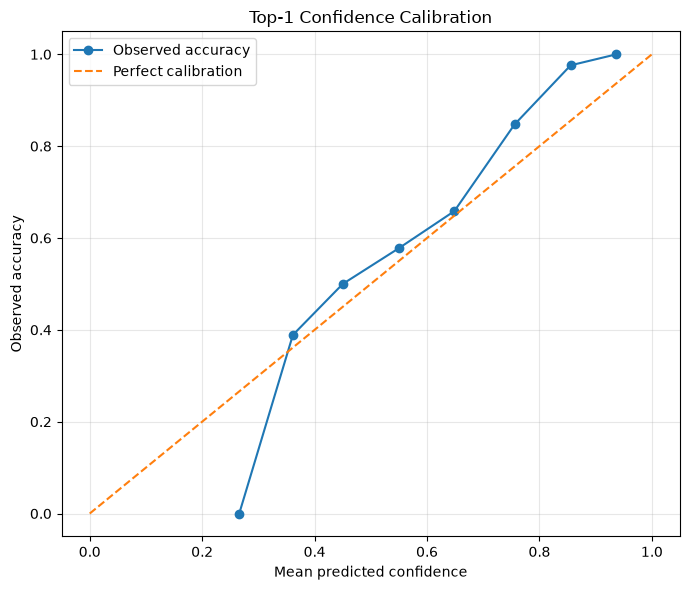

In [35]:
# Step 13B: Evaluate probability calibration

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.metrics import log_loss

# True labels and predicted probabilities
y_test_array = np.asarray(y_test)
probabilities = final_model.predict_proba(X_test)
classes = final_model.classes_

# Convert labels into one-hot format
y_onehot = np.column_stack([
    (y_test_array == label).astype(int)
    for label in classes
])

# Multiclass Brier score
brier_score = np.mean(
    np.sum((probabilities - y_onehot) ** 2, axis=1)
)

# Log loss
test_log_loss = log_loss(
    y_test_array,
    probabilities,
    labels=classes
)

# Confidence calibration for the top prediction
predicted_indices = np.argmax(probabilities, axis=1)
top_confidence = np.max(probabilities, axis=1)
top_correct = (
    classes[predicted_indices] == y_test_array
).astype(int)

results = []

bin_edges = np.linspace(0, 1, 11)

for i in range(len(bin_edges) - 1):
    lower = bin_edges[i]
    upper = bin_edges[i + 1]

    if i == len(bin_edges) - 2:
        mask = (
            (top_confidence >= lower)
            & (top_confidence <= upper)
        )
    else:
        mask = (
            (top_confidence >= lower)
            & (top_confidence < upper)
        )

    if mask.sum() > 0:
        results.append({
            "Confidence_Range": f"{lower:.1f}-{upper:.1f}",
            "Number_of_Predictions": int(mask.sum()),
            "Mean_Confidence": top_confidence[mask].mean(),
            "Actual_Accuracy": top_correct[mask].mean()
        })

calibration_results = pd.DataFrame(results)

print("Multiclass Brier Score:", round(brier_score, 4))
print("Test Log Loss:", round(test_log_loss, 4))

display(calibration_results.round(4))

# Plot confidence versus observed accuracy
plt.figure(figsize=(7, 6))

plt.plot(
    calibration_results["Mean_Confidence"],
    calibration_results["Actual_Accuracy"],
    marker="o",
    label="Observed accuracy"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted confidence")
plt.ylabel("Observed accuracy")
plt.title("Top-1 Confidence Calibration")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
# Step 13C: Calculate Expected Calibration Error (ECE)

import numpy as np

confidence = np.max(test_probabilities, axis=1)
predicted_labels = final_model.classes_[
    np.argmax(test_probabilities, axis=1)
]
correct = (predicted_labels == np.asarray(y_test)).astype(int)

bin_edges = np.linspace(0, 1, 11)
ece = 0.0

for i in range(len(bin_edges) - 1):
    lower, upper = bin_edges[i], bin_edges[i + 1]

    if i == len(bin_edges) - 2:
        mask = (confidence >= lower) & (confidence <= upper)
    else:
        mask = (confidence >= lower) & (confidence < upper)

    if mask.sum() > 0:
        bin_confidence = confidence[mask].mean()
        bin_accuracy = correct[mask].mean()
        bin_weight = mask.mean()

        ece += bin_weight * abs(bin_accuracy - bin_confidence)

print(f"Expected Calibration Error (ECE): {ece:.4f}")
print(f"ECE percentage: {ece * 100:.2f}%")

Expected Calibration Error (ECE): 0.0733
ECE percentage: 7.33%


In [37]:
# Step 14A: Save the fitted model and metadata

from pathlib import Path
import joblib
import json
import sklearn

# Create an artifacts directory inside the project
ARTIFACTS_DIR = Path("artifacts")
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

# Save the complete fitted pipeline
model_path = ARTIFACTS_DIR / "career_guidance_model.joblib"
joblib.dump(final_model, model_path)

# Save essential metadata
metadata = {
    "project_name": "AI-Powered Career Guidance Platform",
    "model_type": type(final_model).__name__,
    "prediction_target": "recommended_career_domain",
    "number_of_features": int(X_train.shape[1]),
    "number_of_career_domains": int(len(final_model.classes_)),
    "career_domains": final_model.classes_.tolist(),
    "cross_validation_accuracy": 0.8438,
    "cross_validation_macro_f1": 0.8429,
    "test_accuracy": 0.8333,
    "test_macro_f1": 0.8314,
    "test_multiclass_brier_score": 0.2291,
    "test_log_loss": 0.4677,
    "test_ece_10_bins": 0.0733,
    "scikit_learn_version": sklearn.__version__
}

metadata_path = ARTIFACTS_DIR / "model_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)

print("Model saved:", model_path.resolve())
print("Metadata saved:", metadata_path.resolve())
print("Model file size:", round(model_path.stat().st_size / 1024, 2), "KB")

Model saved: C:\B-TECH\ACADEMIC\MLLAB\ML_PROJECT\AI_Career_Guidance_Dataset_Package\AI_Career_Guidance_Dataset\artifacts\career_guidance_model.joblib
Metadata saved: C:\B-TECH\ACADEMIC\MLLAB\ML_PROJECT\AI_Career_Guidance_Dataset_Package\AI_Career_Guidance_Dataset\artifacts\model_metadata.json
Model file size: 59975.18 KB


In [38]:

# Step 14B: Reload and verify the saved model

import joblib
import numpy as np
from pathlib import Path

# Load the saved model
model_path = Path("artifacts/career_guidance_model.joblib")
loaded_model = joblib.load(model_path)

# Generate predictions using both models
original_predictions = final_model.predict(X_test)
loaded_predictions = loaded_model.predict(X_test)

# Verify prediction consistency
predictions_match = np.array_equal(
    original_predictions,
    loaded_predictions
)

print("Loaded model type:", type(loaded_model).__name__)
print("Number of career domains:", len(loaded_model.classes_))
print("Original and loaded predictions match:", predictions_match)
print("Total test samples:", len(X_test))

assert predictions_match, "Error: Saved model predictions do not match!"
print("\nModel reload verification successful!")


Loaded model type: VotingClassifier
Number of career domains: 12
Original and loaded predictions match: True
Total test samples: 480

Model reload verification successful!


In [39]:
# Step 15A: Inspect the required student profile features

print("Total required features:", len(X_train.columns))
print("\nRequired feature names and data types:")

display(
    pd.DataFrame({
        "Feature": X_train.columns,
        "Data_Type": X_train.dtypes.astype(str).values
    }).reset_index(drop=True)
)

Total required features: 25

Required feature names and data types:


,Feature,Data_Type
0,age_group,str
1,education_level,str
2,experience_stage,str
3,region_type,str
4,interest_technology,float64
5,interest_data,float64
6,interest_problem_solving,float64
7,interest_creativity,float64
8,interest_people,float64
9,interest_helping,float64


In [40]:

# Step 15B: Generate Top-3 career recommendations

import pandas as pd
import numpy as np

# Create a sample student profile
student_profile = {
    "age_group": "18-21",
    "education_level": "Undergraduate",
    "experience_stage": "Beginner",
    "region_type": "Urban",

    "interest_technology": 5.0,
    "interest_data": 4.5,
    "interest_problem_solving": 5.0,
    "interest_creativity": 3.5,
    "interest_people": 3.0,
    "interest_helping": 3.0,

    "aptitude_logical": 4.5,
    "aptitude_numerical": 4.0,
    "aptitude_verbal": 3.5,
    "aptitude_spatial": 4.0,
    "aptitude_critical_thinking": 4.5,

    "trait_openness": 4.0,
    "trait_conscientiousness": 4.0,
    "trait_extraversion": 3.0,
    "trait_agreeableness": 3.5,
    "trait_emotional_stability": 4.0,

    "skill_programming": 4.0,
    "skill_data_analysis": 4.5,
    "skill_research": 3.5,
    "skill_communication": 3.5,
    "skill_leadership": 3.0
}

# Convert to DataFrame in the exact training feature order
student_df = pd.DataFrame(
    [student_profile],
    columns=X_train.columns
)

# Predict probabilities using the saved model
probabilities = loaded_model.predict_proba(student_df)[0]
career_domains = loaded_model.classes_

# Sort career domains by predicted probability
top_indices = np.argsort(probabilities)[::-1][:3]

recommendations = pd.DataFrame({
    "Rank": range(1, 4),
    "Career_Domain": career_domains[top_indices],
    "Model_Score_Percent": (
        probabilities[top_indices] * 100
    ).round(2)
})

print("TOP 3 CAREER DOMAIN PREDICTIONS")
display(recommendations)


TOP 3 CAREER DOMAIN PREDICTIONS


,Rank,Career_Domain,Model_Score_Percent
0,1,Software Development,77.76
1,2,Engineering & Core Technology,5.15
2,3,UI/UX Design,3.78
